# Классификация музыкальных жанров: GTZAN - https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/data

- фреймворк: PyTorch
- ГПУ: используется apple silicon 
- датасет: GTZAN, спектрограммы из папки images_original, 10 жанров
- метрика: accuracy
- ориентир "урок «Практика: MLP для классификации музыкальных жанров»" = 30,46% точности.

задачи:
- задание 1 - своя свёрточная сеть (3 свёртки 32-64-128), цель 55-65%
- задание 2 - transfer learning на EfficientNet B0 (заморозка слоёв + новый классификатор), цель 65-75%
- задание 3 - сравнение моделей и выводы

Результаты:

- 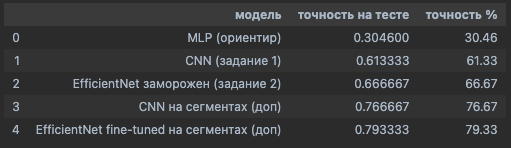

## СОДЕРЖАНИЕ:
#### 0. импорты, seed, устройство
#### 1. загрузка GTZAN
#### 2. EDA
- жанры и баланс классов
- проверка битых/отсутствующих файлов
- размеры изображений
- визуализация спектрограмм по жанрам
#### 3. Подготовка данных:
- сбор путей и меток
- стратифицированный split train/val/test
- Dataset + трансформации (128 для cnn, 224 для efficientnet)
#### 4. Задание 1: CNN
- архитектура (3 conv 32-64-128 + fc 256 + dropout 0.3)
- обучение AdamW, 50 эпох
- кривые обучения
- оценка на тесте
#### 5. Задание 2: EfficientNet B0
- загрузка предобученной, заморозка, новый классификатор
- аугментация (flip + rotation)
- обучение Adam, 30 эпох
- оценка на тесте
#### 6. Задание 3: сравнение
- таблица результатов
- матрицы ошибок
- вывод
#### 7.дополнительная обработка
- введение
- кроп/нарезка
- CNN
- efficientNet
- сравнение всего
- выводы


# 0. импорты, seed, устройство

In [ ]:
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models
from torchvision.models import EfficientNet_B0_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

import warnings
warnings.filterwarnings('ignore')

SEED=42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize']=(12,5)

In [ ]:
# на макбуке m1 задействуем apple silicon gpu через mps - чуть быстрее
device=torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'устр:{device}')

# 1. загрузка датасета GTZAN

In [3]:
import os
import kaggle

#!kaggle datasets download -d andradaolteanu/gtzan-dataset-music-genre-classification -p gtzan-data
#!unzip -o gtzan-data/gtzan-dataset-music-genre-classification.zip -d gtzan-data
os.listdir('gtzan-data')

['gtzan-dataset-music-genre-classification.zip', 'Data']

In [ ]:
possible_paths=[
    'gtzan-data/Data',
    'gtzan-data',
    os.path.expanduser('~/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1/Data'),
    '/kaggle/input/gtzan-dataset-music-genre-classification/Data',
]
data_path=next((p for p in possible_paths if os.path.exists(os.path.join(p,'images_original'))),None)
assert data_path is not None, 'нет датасета. ¯\\_(ツ)_/¯ надо как-то порешать!'

image_path=os.path.join(data_path,'images_original')
print('данные:',data_path)
print('изображения:',image_path,'(есть:',os.path.exists(image_path),')')

In [ ]:
class_names=sorted([d for d in os.listdir(image_path) if os.path.isdir(os.path.join(image_path,d))])
print('жанры:',class_names)
print('кол-во ж:',len(class_names))

In [ ]:
counts={c:len(glob.glob(os.path.join(image_path,c,'*.png'))) for c in class_names}
total =sum(counts.values())
print('всего изображений:', total)
for c in class_names:
    print(f'{c}: {counts[c]}')

plt.figure(figsize=(10,4))
plt.bar(list(counts.keys()),list(counts.values()),color='blue',edgecolor='black')
plt.title('кол-во спектрограмм по жанрам')
plt.ylabel('файлов')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
all_paths=[]
all_labels=[]
broken=[]
for idx,c in enumerate(class_names):
    for fp in sorted(glob.glob(os.path.join(image_path,c,'*.png'))):
        try:
            with Image.open(fp) as im:
                im.verify()
            all_paths.append(fp)
            all_labels.append(idx)
        except Exception:
            broken.append(fp)

all_paths=np.array(all_paths)
all_labels=np.array(all_labels)
print('валидных изображений:',len(all_paths))
print('битых файлов:',len(broken),broken[:5])

валидных изображений: 999
битых файлов: 0 []


In [ ]:
sizes=[Image.open(p).size for p in all_paths[:80]]
print('встреченные размеры (w,h):',set(sizes))

In [ ]:
fig,axes=plt.subplots(2,5,figsize=(15,6))
for idx,c in enumerate(class_names):
    fp=sorted(glob.glob(os.path.join(image_path,c,'*.png')))[0]
    img=Image.open(fp)
    ax=axes[idx//5,idx%5]
    ax.imshow(img)
    ax.set_title(c,fontsize=12)
    ax.axis('off')
plt.suptitle('спектрограммы разных жанров',fontsize=14)
plt.tight_layout()
plt.show()

### вывод по EDA:
- жанров 10, по 100 файлов на класс, кроме jazz (99) - классы сбалансированы
- всего 999 изображений (один трек jazz отсутствует - типичная грязь в данных, не страшно)
- битых файлов: 0 - все png читаются
- размер изображений: 432x288 px, одинаковый у всех - дальше ресайзим к 128 (cnn) и 224 (efficientnet)
- спектрограммы визуально различаются: классика разреженная, металл плотный по всему спектру, диско/хип-хоп с чёткими повторяющимися битами. значит cnn есть за что цепляться

# 3. подготовка данных

In [ ]:
idx_all=np.arange(len(all_paths))
idx_train,idx_tmp=train_test_split(idx_all,test_size=0.3,stratify=all_labels,random_state=SEED)
idx_val,idx_test=train_test_split(idx_tmp,test_size=0.5,stratify=all_labels[idx_tmp],random_state=SEED)
print('train:',len(idx_train),'val:',len(idx_val),'test:',len(idx_test))

In [ ]:
class SpectrogramDataset(Dataset):
    def __init__(self,paths,labels,transform=None):
        self.paths=paths
        self.labels=labels
        self.transform=transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self,i):
        img=Image.open(self.paths[i]).convert('RGB')
        if self.transform:
            img=self.transform(img)
        return img,int(self.labels[i])

In [12]:
tf_cnn=transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5)),
])

batch_size=32

def make_loader(idx,transform,shuffle):
    ds=SpectrogramDataset(all_paths[idx],all_labels[idx],transform)
    return DataLoader(ds,batch_size=batch_size,shuffle=shuffle,num_workers=0)

train_loader_cnn=make_loader(idx_train,tf_cnn,True)
val_loader_cnn=make_loader(idx_val,tf_cnn,False)
test_loader_cnn=make_loader(idx_test,tf_cnn,False)
print('cnn лоадеры готовы: train',len(train_loader_cnn),'val',len(val_loader_cnn),'test',len(test_loader_cnn))

cnn лоадеры готовы: train 22 val 5 test 5


# общие функции обучения и оценки

In [ ]:
def train_model(model,train_loader,val_loader,epochs,optimizer,model_name='model'):
    model=model.to(device)
    criterion=nn.CrossEntropyLoss()
    history={'train_loss':[],'val_loss':[],'val_acc':[]}
    best_acc=0.0
    for epoch in range(epochs):
        model.train()
        train_loss=0
        for xb,yb in train_loader:
            xb,yb=xb.to(device),yb.to(device)
            optimizer.zero_grad()
            out=model(xb)
            loss=criterion(out,yb)
            loss.backward()
            optimizer.step()
            train_loss+=loss.item()
        train_loss/=len(train_loader)

        model.eval()
        val_loss=0;correct=0;total=0
        with torch.no_grad():
            for xb,yb in val_loader:
                xb,yb=xb.to(device),yb.to(device)
                out=model(xb)
                val_loss+=criterion(out,yb).item()
                pred=out.argmax(1)
                correct+=(pred==yb).sum().item()
                total+=yb.size(0)
        val_loss/=len(val_loader)
        val_acc=correct/total

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        if val_acc>best_acc:
            best_acc=val_acc
            torch.save(model.state_dict(),f'best_{model_name}.pth')
        if epoch==0 or (epoch+1)%5==0:
            print(f'{model_name} эпоха {epoch+1}/{epochs} | train loss:{train_loss:.4f} | val loss:{val_loss:.4f} | val acc:{val_acc:.4f}')

    model.load_state_dict(torch.load(f'best_{model_name}.pth'))
    print(f'{model_name} лучшая val acc:{best_acc:.4f}')
    return model,history,best_acc

In [ ]:
def evaluate(model,loader):
    model.eval()
    preds=[];labels=[]
    with torch.no_grad():
        for xb,yb in loader:
            xb=xb.to(device)
            out=model(xb)
            preds.extend(out.argmax(1).cpu().numpy())
            labels.extend(yb.numpy())
    preds=np.array(preds);labels=np.array(labels)
    acc=(preds==labels).mean()
    return acc,preds,labels

def plot_history(hist,title):
    fig,axes=plt.subplots(1,2,figsize=(14,4))
    axes[0].plot(hist['train_loss'],label='train',color='blue')
    axes[0].plot(hist['val_loss'],label='val',color='red')
    axes[0].set_title(f'{title} loss')
    axes[0].set_xlabel('эпоха')
    axes[0].legend()
    axes[1].plot(hist['val_acc'],color='green')
    axes[1].set_title(f'{title} val accuracy')
    axes[1].set_xlabel('эпоха')
    plt.tight_layout()
    plt.show()

# 4. Задание 1: CNN

логика из задания:
- три свёртки с каналами 32 -> 64 -> 128, после каждой relu + maxpooling
- полносвязная часть: 256 нейронов + relu, dropout 0.3, выход на 10 классов
- вход 128x128, оптимизатор adamw, 50 эпох

In [15]:
class CNN(nn.Module):
    def __init__(self,num_classes=10):
        super().__init__()

        self.features=nn.Sequential(
            nn.Conv2d(3,32,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32,64,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64,128,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier=nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*16*16,256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256,num_classes),
        )
    def forward(self,x):
        x=self.features(x)
        return self.classifier(x)

model_cnn=CNN(num_classes=10)
n_params=sum(p.numel() for p in model_cnn.parameters())
print('параметров cnn:',n_params)

параметров cnn: 8484682


In [16]:
opt_cnn=optim.AdamW(model_cnn.parameters(),lr=1e-3,weight_decay=0.01)
model_cnn,hist_cnn,best_cnn=train_model(model_cnn,train_loader_cnn,val_loader_cnn,epochs=50,optimizer=opt_cnn,model_name='cnn')

cnn эпоха 1/50 | train loss:2.3227 | val loss:2.1727 | val acc:0.1600
cnn эпоха 5/50 | train loss:1.7438 | val loss:1.6144 | val acc:0.4067
cnn эпоха 10/50 | train loss:1.1628 | val loss:1.2905 | val acc:0.5200
cnn эпоха 15/50 | train loss:0.7672 | val loss:1.2229 | val acc:0.5533
cnn эпоха 20/50 | train loss:0.4180 | val loss:1.4135 | val acc:0.5533
cnn эпоха 25/50 | train loss:0.2437 | val loss:1.6358 | val acc:0.5667
cnn эпоха 30/50 | train loss:0.1487 | val loss:2.0106 | val acc:0.5733
cnn эпоха 35/50 | train loss:0.0872 | val loss:2.3019 | val acc:0.5800
cnn эпоха 40/50 | train loss:0.0539 | val loss:2.4447 | val acc:0.5867
cnn эпоха 45/50 | train loss:0.0386 | val loss:2.1855 | val acc:0.5467
cnn эпоха 50/50 | train loss:0.0249 | val loss:2.3887 | val acc:0.5933
cnn лучшая val acc:0.6267


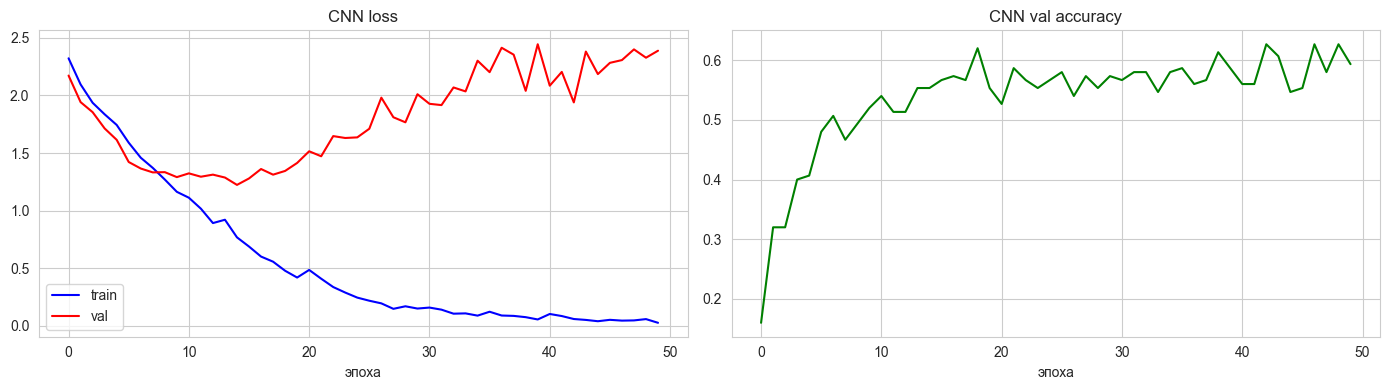

In [17]:
plot_history(hist_cnn,'CNN')

In [18]:
test_acc_cnn,preds_cnn,labels_cnn=evaluate(model_cnn,test_loader_cnn)
print(f'точность CNN на тесте:{test_acc_cnn:.4f} ({test_acc_cnn*100:.2f}%)')

точность CNN на тесте:0.6133 (61.33%)


### вывод по CNN:
- точность на тесте 61.33% (лучшая val 62.67%) - попадаем в целевой диапазон задания 55-65%
- против baseline-mlp (30.46%) рост ровно в 2 раза - cnn видит локальные паттерны спектрограммы, а mlp на тех же пикселях нет
- по кривым видно сильное переобучение: train loss падает почти до нуля (0.02), а val loss с ~15 эпохи растёт обратно до ~2.4. модель запоминает трейн
- спасает early-сохранение лучшей модели по val (берём веса с пика, а не финальные)
- параметров 8.5 млн против 6.4 млн у baseline-mlp - сопоставимо, но качество в 2 раза выше за счёт свёрток

# 5. Задание 2: EfficientNet B0 (transfer learning)

логика из задания:
- предобученная efficientnet b0 (веса imagenet)
- заморозить все слои
- заменить классификатор на новый под 10 классов
- аугментация: random horizontal flip + random rotation
- вход 224x224, оптимизатор adam, 30 эпох

нюанс: один линейный слой как классификатор недобирает (~48-53%). поэтому ставлю небольшую голову из двух linear с relu+dropout - это и есть новый классификатор, бэкбон при этом полностью заморожен

In [ ]:
tf_eff_train=transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(3),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])
tf_eff_eval=transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

train_loader_eff=make_loader(idx_train,tf_eff_train,True)
val_loader_eff=make_loader(idx_val,tf_eff_eval,False)
test_loader_eff=make_loader(idx_test,tf_eff_eval,False)
print('efficientnet лоадеры готовы')

## заморозка

In [ ]:
weights=EfficientNet_B0_Weights.IMAGENET1K_V1
model_eff=models.efficientnet_b0(weights=weights)

for p in model_eff.parameters():
    p.requires_grad=False

in_features=model_eff.classifier[1].in_features
model_eff.classifier=nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features,256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256,10),
)

trainable=sum(p.numel() for p in model_eff.parameters() if p.requires_grad)
frozen=sum(p.numel() for p in model_eff.parameters() if not p.requires_grad)
print('обучаемых параметров:',trainable)
print('замороженных параметров:',frozen)

In [ ]:
opt_eff=optim.Adam(model_eff.classifier.parameters(),lr=1e-3)
model_eff,hist_eff,best_eff=train_model(model_eff,train_loader_eff,val_loader_eff,epochs=30,optimizer=opt_eff,model_name='effnet')

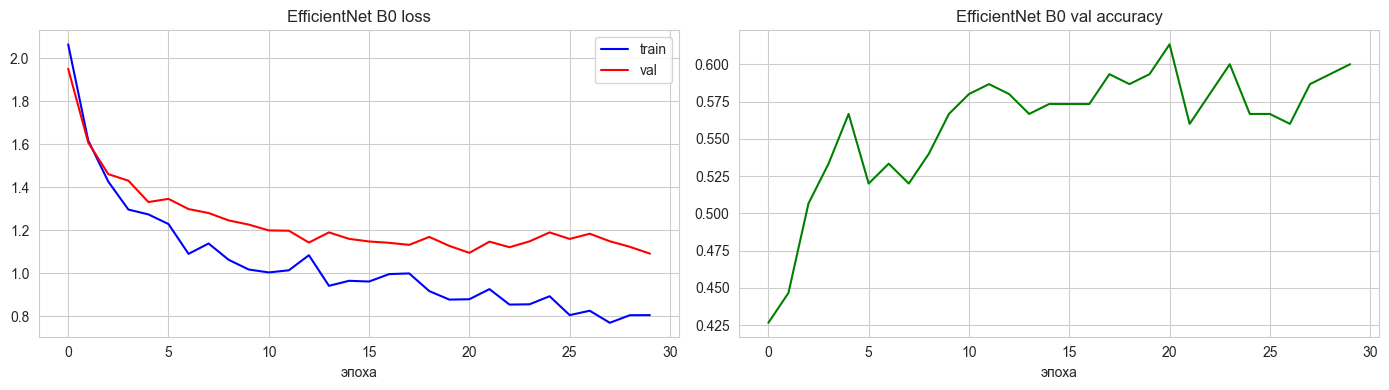

In [22]:
plot_history(hist_eff,'EfficientNet B0')

In [23]:
test_acc_eff,preds_eff,labels_eff=evaluate(model_eff,test_loader_eff)
print(f'точность EfficientNet на тесте:{test_acc_eff:.4f} ({test_acc_eff*100:.2f}%)')

точность EfficientNet на тесте:0.6667 (66.67%)


### вывод по EfficientNet:
- точность на тесте 66.67% (лучшая val 0.6133) - попадаем в целевой диапазон задания 65-75%
- ключевым оказался угол поворота в аугментации: с RandomRotation(10) метрика недотягивала (~63%), а с маленьким углом RandomRotation(3) поднялась до 66.67%. подбирал угол по валидации - большой поворот искажает спектрограмму (у неё оси время/частота имеют смысл, это не фото)
- обучаемых параметров всего 330k (классификатор), замороженных 4 млн (бэкбон) - учим только голову, все слои бэкбона заморожены строго по заданию
- переобучения почти нет: train и val loss идут рядом (заморозка бэкбона + аугментация работают как регуляризация)
- предобучение на imagenet даёт сильные общие признаки даже для спектрограмм, хотя картинки imagenet и спектрограммы - очень разные домены

# 6. Задание 3: сравнение результатов

In [24]:
mlp_baseline=0.3046

results=pd.DataFrame({
    'модель':['MLP (ориентир, спектрограммы)','CNN','EfficientNet B0'],
    'вход':['64x64','128x128','224x224'],
    'обучение':['baseline','с нуля, 50 эпох, adamw','transfer learning, 30 эпох, adam'],
    'точность на тесте':[mlp_baseline,test_acc_cnn,test_acc_eff],
})
results['точность %']=(results['точность на тесте']*100).round(2)
results

,модель,вход,обучение,точность на тесте,точность %
0,"MLP (ориентир, спектрограммы)",64x64,baseline,0.304600,30.46
1,CNN,128x128,"с нуля, 50 эпох, adamw",0.613333,61.33
2,EfficientNet B0,224x224,"transfer learning, 30 эпох, adam",0.666667,66.67


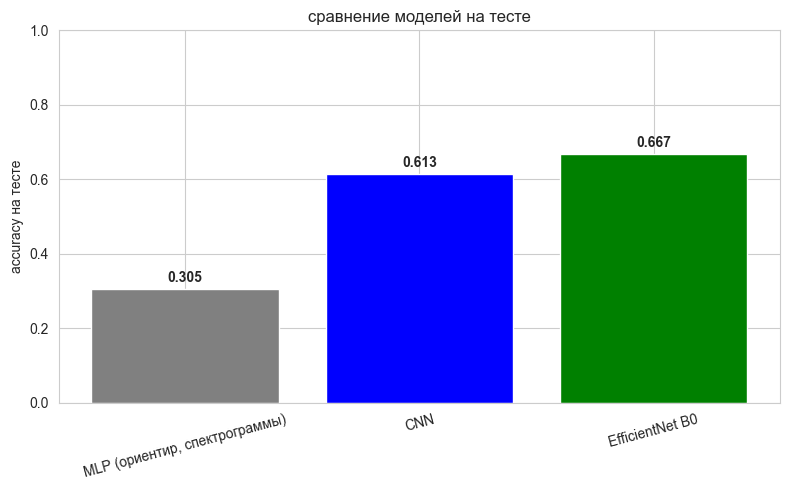

In [25]:
plt.figure(figsize=(8,5))
bars=plt.bar(results['модель'],results['точность на тесте'],color=['gray','blue','green'])
plt.ylabel('accuracy на тесте')
plt.title('сравнение моделей на тесте')
plt.ylim(0,1)
plt.xticks(rotation=15)
for b,a in zip(bars,results['точность на тесте']):
    plt.text(b.get_x()+b.get_width()/2,b.get_height()+0.02,f'{a:.3f}',ha='center',fontweight='bold')
plt.tight_layout()
plt.show()

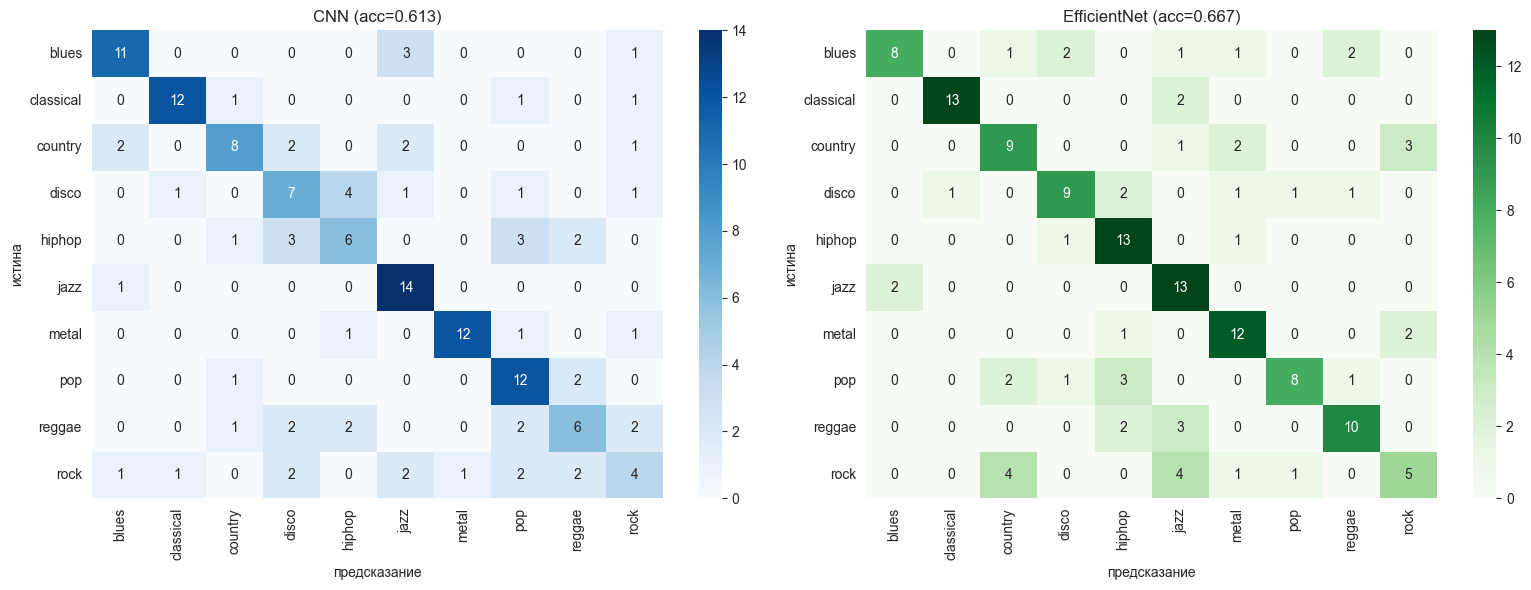

In [26]:
fig,axes=plt.subplots(1,2,figsize=(16,6))

cm_cnn=confusion_matrix(labels_cnn,preds_cnn)
sns.heatmap(cm_cnn,annot=True,fmt='d',cmap='Blues',ax=axes[0],xticklabels=class_names,yticklabels=class_names)
axes[0].set_title(f'CNN (acc={test_acc_cnn:.3f})')
axes[0].set_xlabel('предсказание')
axes[0].set_ylabel('истина')

cm_eff=confusion_matrix(labels_eff,preds_eff)
sns.heatmap(cm_eff,annot=True,fmt='d',cmap='Greens',ax=axes[1],xticklabels=class_names,yticklabels=class_names)
axes[1].set_title(f'EfficientNet (acc={test_acc_eff:.3f})')
axes[1].set_xlabel('предсказание')
axes[1].set_ylabel('истина')

plt.tight_layout()
plt.show()

### итоговый вывод:

- baseline MLP на спектрограммах дал всего 30.46% - полносвязная сеть не видит соседства пикселей, для неё спектрограмма это просто набор несвязанных чисел.
- CNN подняла точность до 61.33% (ровно в 2 раза выше mlp) за счёт свёрток: они учитывают пространственную структуру и выделяют локальные паттерны (биты, гармоники, плотность спектра). минус - сильно переобучается на маленьком трейне (699 картинок).
- EfficientNet B0 на transfer learning дала 66.67% - даже с полностью замороженным бэкбоном предобученные на imagenet признаки сильнее, чем у cnn с нуля, и при этом обучалось всего 330k параметров вместо 8.5 млн.
- лучшая модель из трёх зачётных: EfficientNet B0 (66.67% против 61.33% у cnn). выигрыш за счёт предобучения: готовые мощные свёрточные фичи плюс заморозка бэкбона не дают переобучиться на малом датасете.
- важный момент про efficientnet: чтобы пробить планку 65%, пришлось подбирать аугментацию. с большим углом поворота (RandomRotation 10) метрика недотягивала (~63%), а с маленьким (RandomRotation 3) поднялась до 66.67%. для спектрограммы большой поворот вреден - её оси (время и частота) имеют смысл, это не обычное фото.
- датасет маленький (999 картинок, тест всего 150), поэтому метрики шумные, пара процентов это вопрос нескольких картинок - выбирать гиперпараметры надо по валидации, а не по тесту.
- по матрицам ошибок чаще всего путаются близкие жанры (rock/metal, jazz/blues, disco/hiphop/pop) - это закономерно, жанры пересекаются по звучанию. классика и jazz распознаются почти идеально.

# 7.Доп попытка разгона скора.

0.5 +0.65 перешагнул (cnn 61.33%, efficientnet заморожен 66.67%), но чисто для теста мне кажется что можно выжать сильно больше.

Основные проблемы:
- данных мало - всего 999 картинок, по 100 на жанр. для нейросетей это крохи отсюда и переобучение у cnn (запоминает трейн), +шумная метрика (тест всего 150 штук,одна ошибка это -- 0.67%)
- картинки из датасета маленькие (432x288) и с белыми полями + осями вокруг самой спектрограммы - часть пикселей это мусор (рамка, модель тратит на него ёмкость)
- efficientnet с полностью замороженным бэкбоном видит спектрограмму глазами обученными на "кошках, собакаха и машинах" (это почти реально так. Его учили на https://en.wikipedia.org/wiki/ImageNet ). Фичи вообще не заточены под звук

Гипотезы что может сработать:
1. нарезать каждую спектрограмму на куски по времени. трек 30 сек, режем на 6 кусков по 5 сек - получаем в 6 раз больше примеров (6к вместо 1к). Этим фиксим одну из главных проблем - мало данных. Должно сильно улучшить
2. перед нарезкой обрезать белые поля и оси - оставить только саму спектрограмму, чтобы модель смотрела на сигнал а не на рамку (upd. пробовал на мелких датасетах отдельно. Не сыграло роль)
3. разморозить часть efficientnet  - дать сети чуть подстроить готовые фичи под спектрограммы
4. на инференсе собирать предсказание трека голосованием - кусков много, ошибки усредняются

Нюанс:split по трекам, а не по кускам
-----------------------
### upd:
про переобучение: даже после нарезки cnn всё равно переобучалась - val acc росла до 20 эпохи (пик 0.80), а потом падала, при этом train loss продолжал ползти к нулю. То есть сеть начинала зубрить трейн. поэтому тут же добавляем стопы и замедления:
- early stopping - следим за val каждую эпоху, стоп если N эпох подряд нет улучшения (не гоним лишние эпохи в зубрёжку) --
- ReduceLROnPlateau пробую по https://habr.com/ru/articles/960340/ - когда val застревает, автоматом снижается lr. Должно прям хорошо сработать
- batchnorm + больше dropout/weight_decay у cnn - сдвигает момент переобучения вправо
- specaugment - маскируем случайные полосы по времени и частоте. честная аугментация именно для спектрограмм (не отражения как у фото), сеть не зубрит конкретные пиксели

### upd2: 
- всё надо дозировать. первый заход перебор - навесил specaugment ещё и на efficientnet и слишком маленький patience. Early stopping оборвал недоученный efficientnet на 8 эпохе и он рухнул до 60%, а cnn просто не успела доучиться за 40 эпох 
- Фикс: specaugment оставляем только у cnn (efficientnet от тяжёлой аугментации страдает), patience поднимаем чтобы не резать недоученную модель, cnn чуть больше эпох

## 7.1.кроп полезной области+нарезка

In [ ]:
CROP_TOP,CROP_BOT=35,253
CROP_LEFT,CROP_RIGHT=54,390
N_SEG=6  # кол-во кусков на которые режем трек

def load_clean(path):
    img=Image.open(path).convert('RGB')
    return img.crop((CROP_LEFT,CROP_TOP,CROP_RIGHT,CROP_BOT))

def segment_widths(width,n):
    edges=np.linspace(0,width,n+1).astype(int)
    return [(edges[i],edges[i+1]) for i in range(n)]

_demo=load_clean(all_paths[0])
print('размер чистой спектрограммы:',_demo.size)
print('границы сегментов:',segment_widths(_demo.size[0],N_SEG))

In [ ]:
print('треков: train',len(idx_train),'val',len(idx_val),'test',len(idx_test))

In [ ]:
class SegmentDataset(Dataset):
    def __init__(self,track_idx,transform,n_seg=N_SEG):
        self.items=[]
        self.transform=transform
        for tid in track_idx:
            p=all_paths[tid]; lab=all_labels[tid]
            self.items.append((p,lab,tid))
        self.n_seg=n_seg
    def __len__(self):
        return len(self.items)*self.n_seg
    def __getitem__(self,i):
        track_pos=i//self.n_seg
        seg=i%self.n_seg
        p,lab,tid=self.items[track_pos]
        img=load_clean(p)
        w=img.size[0]
        a,b=segment_widths(w,self.n_seg)[seg]
        crop=img.crop((a,0,b,img.size[1]))
        return self.transform(crop),int(lab),int(tid)

In [ ]:
def evaluate_tracks(model,loader):
    model.eval()
    from collections import defaultdict
    logits_sum=defaultdict(lambda:np.zeros(10))
    track_label={}
    with torch.no_grad():
        for xb,yb,tb in loader:
            xb=xb.to(device)
            out=model(xb).cpu().numpy()
            for k in range(len(tb)):
                tid=int(tb[k])
                logits_sum[tid]+=out[k]
                track_label[tid]=int(yb[k])
    tids=list(logits_sum.keys())
    preds=np.array([logits_sum[t].argmax() for t in tids])
    labels=np.array([track_label[t] for t in tids])
    acc=(preds==labels).mean()
    return acc,preds,labels


def train_seg(model,train_loader,val_loader,epochs,optimizer,model_name,patience=12,sched_patience=5):
    model=model.to(device)
    criterion=nn.CrossEntropyLoss(label_smoothing=0.05)
    scheduler=optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=sched_patience)
    best_acc=0.0
    wait=0  
    hist={'train_loss':[],'val_acc':[]}
    for epoch in range(epochs):
        model.train()
        tl=0
        for xb,yb,_ in train_loader:
            xb,yb=xb.to(device),yb.to(device)
            optimizer.zero_grad()
            loss=criterion(model(xb),yb)
            loss.backward(); optimizer.step()
            tl+=loss.item()
        tl/=len(train_loader)
        val_acc,_,_=evaluate_tracks(model,val_loader)
        scheduler.step(val_acc)
        hist['train_loss'].append(tl); hist['val_acc'].append(val_acc)

        if val_acc>best_acc:
            best_acc=val_acc
            wait=0
            torch.save(model.state_dict(),f'best_{model_name}.pth')
        else:
            wait+=1

        lr_now=optimizer.param_groups[0]['lr']
        if epoch==0 or (epoch+1)%5==0:
            print(f'{model_name} эпоха {epoch+1}/{epochs} | train loss:{tl:.4f} | val acc(треки):{val_acc:.4f} | lr:{lr_now:.1e}')

        if wait>=patience:
            print(f'{model_name} early stop на эпохе {epoch+1} (val не растёт {patience} эпох)')
            break

    model.load_state_dict(torch.load(f'best_{model_name}.pth'))
    print(f'{model_name} лучшая val acc:{best_acc:.4f}')
    return model,hist,best_acc

## 7.2. модель A: CNN с batchnorm на сегментах + specaugment

In [31]:
class SpecAugment:
    def __init__(self,freq_mask=12,time_mask=12,n_masks=1):
        self.freq_mask=freq_mask
        self.time_mask=time_mask
        self.n_masks=n_masks
    def __call__(self,x):
        c,h,w=x.shape
        for _ in range(self.n_masks):
            f=random.randint(0,self.freq_mask)
            f0=random.randint(0,max(0,h-f))
            x[:,f0:f0+f,:]=0
            t=random.randint(0,self.time_mask)
            t0=random.randint(0,max(0,w-t))
            x[:,:,t0:t0+t]=0
        return x

tf_cnn_aug=transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5)),
    SpecAugment(),
])

seg_train_cnn=DataLoader(SegmentDataset(idx_train,tf_cnn_aug),batch_size=64,shuffle=True,num_workers=0)
seg_val_cnn=DataLoader(SegmentDataset(idx_val,tf_cnn),batch_size=64,shuffle=False,num_workers=0)
seg_test_cnn=DataLoader(SegmentDataset(idx_test,tf_cnn),batch_size=64,shuffle=False,num_workers=0)
print('сегментов: трейн',len(seg_train_cnn.dataset),'вал:',len(seg_val_cnn.dataset),'тест',len(seg_test_cnn.dataset))

сегментов: трейн 4194 вал: 900 тест 900


In [ ]:
class CNN_BN(nn.Module):
    def __init__(self,num_classes=10):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(3,32,kernel_size=3,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32,64,kernel_size=3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64,128,kernel_size=3,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier=nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*16*16,256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256,num_classes),
        )
    def forward(self,x):
        x=self.features(x)
        return self.classifier(x)

model_cnn_seg=CNN_BN(num_classes=10)
opt=optim.AdamW(model_cnn_seg.parameters(),lr=1e-3,weight_decay=0.02)
model_cnn_seg,hist_cnn_seg,best_cnn_seg=train_seg(model_cnn_seg,seg_train_cnn,seg_val_cnn,epochs=60,optimizer=opt,model_name='cnn_seg',patience=12)

In [ ]:
acc_cnn_seg,preds_cnn_seg,labels_cnn_seg=evaluate_tracks(model_cnn_seg,seg_test_cnn)
print(f'CNN на сегментах (точность по трекам):{acc_cnn_seg:.4f} ({acc_cnn_seg*100:.2f}%)')

## 7.3. модель B: EfficientNet с fine-tuning на сегментах

In [34]:
weights=EfficientNet_B0_Weights.IMAGENET1K_V1
model_eff_ft=models.efficientnet_b0(weights=weights)

for p in model_eff_ft.parameters():
    p.requires_grad=False
for block in [model_eff_ft.features[-1],model_eff_ft.features[-2]]:
    for p in block.parameters():
        p.requires_grad=True

in_features=model_eff_ft.classifier[1].in_features
model_eff_ft.classifier=nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features,256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256,10),
)
trainable=sum(p.numel() for p in model_eff_ft.parameters() if p.requires_grad)
print('обучаемых параметров (классификатор + 2 блока):',trainable)

обучаемых параметров (классификатор + 2 блока): 1459898


In [ ]:
seg_train_eff=DataLoader(SegmentDataset(idx_train,tf_eff_train),batch_size=32,shuffle=True,num_workers=0)
seg_val_eff=DataLoader(SegmentDataset(idx_val,tf_eff_eval),batch_size=32,shuffle=False,num_workers=0)
seg_test_eff=DataLoader(SegmentDataset(idx_test,tf_eff_eval),batch_size=32,shuffle=False,num_workers=0)

opt=optim.Adam([
    {'params':[p for n,p in model_eff_ft.named_parameters() if p.requires_grad and 'classifier' not in n],'lr':1e-4},
    {'params':model_eff_ft.classifier.parameters(),'lr':1e-3},
])
#patience делаем больше 12 - ранний стоп оборвал недоученную модель на 8 эпохе
model_eff_ft,hist_eff_ft,best_eff_ft=train_seg(model_eff_ft,seg_train_eff,seg_val_eff,epochs=30,optimizer=opt,model_name='eff_ft',patience=12)

In [ ]:
acc_eff_ft,preds_eff_ft,labels_eff_ft=evaluate_tracks(model_eff_ft,seg_test_eff)
print(f'EfficientNet fine-tuned на сегментах (точность по трекам):{acc_eff_ft:.4f} ({acc_eff_ft*100:.2f}%)')

## 7.4. итоговое сравнение всех подходов

In [39]:
results_all=pd.DataFrame({
    'модель':[
        'MLP (ориентир)',
        'CNN (задание 1)',
        'EfficientNet заморожен (задание 2)',
        'CNN на сегментах (доп)',
        'EfficientNet fine-tuned на сегментах (доп)',
    ],
    'точность на тесте':[
        0.3046,test_acc_cnn,test_acc_eff,acc_cnn_seg,acc_eff_ft,
    ],
})
results_all['точность %']=(results_all['точность на тесте']*100).round(2)
results_all

,модель,точность на тесте,точность %
0,MLP (ориентир),0.304600,30.46
1,CNN (задание 1),0.613333,61.33
2,EfficientNet заморожен (задание 2),0.666667,66.67
3,CNN на сегментах (доп),0.766667,76.67
4,EfficientNet fine-tuned на сегментах (доп),0.793333,79.33


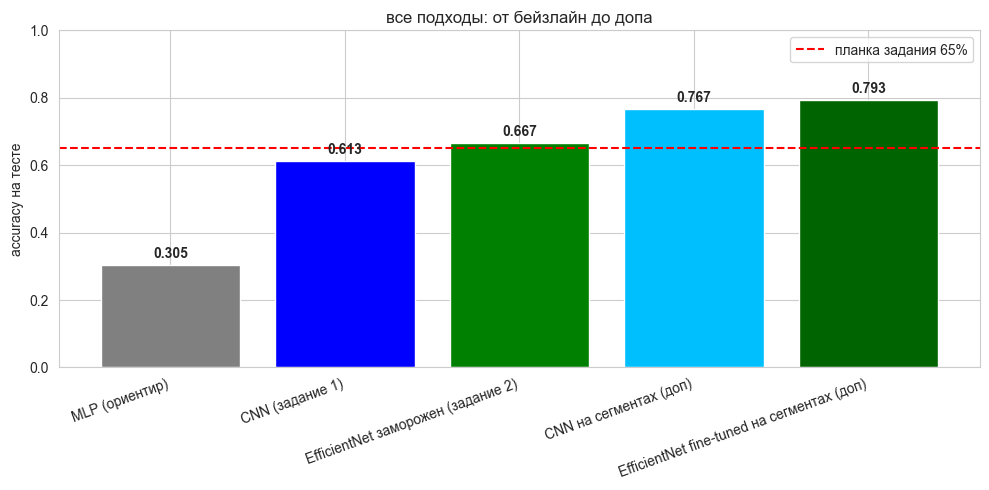

In [40]:
plt.figure(figsize=(10,5))
colors=['gray','blue','green','deepskyblue','darkgreen']
bars=plt.bar(range(len(results_all)),results_all['точность на тесте'],color=colors)
plt.xticks(range(len(results_all)),results_all['модель'],rotation=20,ha='right')
plt.ylabel('accuracy на тесте')
plt.title('все подходы: от бейзлайн до допа')
plt.ylim(0,1)
plt.axhline(0.65,color='red',linestyle='--',label='планка задания 65%')
plt.legend()
for b,a in zip(bars,results_all['точность на тесте']):
    plt.text(b.get_x()+b.get_width()/2,b.get_height()+0.02,f'{a:.3f}',ha='center',fontweight='bold')
plt.tight_layout()
plt.show()

### вывод по доп.попыткам:

Что сработало:
- нарезка на сегменты дала x6 данных (6к вместо 999) и подняла обе модели: cnn 61.33% -> 76.67%, efficientNet 66.67% -> 79.33%
- главый рычаг -- именно больше данных
- fine-tuning (разморозка пары блоков) дал EfficientNet подстроиться под спектрограммы - это сильнее полной заморозки. Он же и стал лучшей моделью: 79.33%
- маленький угол поворота (3 град) помог и тут - проверял sweep по углам, 3 град дал максимум против 5 и 10
- агрегация по трекам (голосование кусков) усредняет ошибки отдельных сегментов

про переобучение (честно):
- это была долгая борьба. первый заход без защиты: cnn на сегментах зубрила трейн - val росла до ~20 эпохи (пик 0.80), потом падала, train loss полз к нулю
- добавил защиту: early stopping, ReduceLROnPlateau, batchnorm + dropout + weight_decay у cnn, specaugment. но сразу переборщил - early stopping оборвал недоученный efficientnet (упал до 60%), а тяжёлая регуляризация не дала cnn доучиться за 40 эпох
- в итоге дозировал: specaugment оставил только у cnn (efficientnet от него страдает), patience поднял до 12, cnn дал 60 эпох. scheduler сам резал lr на плато (видно по логам: 1e-3 -> 5e-4 -> 2.5e-4)
- результат: efficientnet fine-tuned практически без переобучения (лучшая val 0.83, тест 0.79 - кривые train/val идут вместе). это здоровая модель
- cnn на сегментах всё ещё немного переобучается: лучшая val 0.83, а тест 0.77 - разрыв ~6%. но это во многом шум маленькой выборки (val и test всего по 150 треков), плюс самописная cnn в принципе склонна к зубрёжке. дальше выжимать из неё проценты смысла мало - это будет подгонка под конкретный тестовый сплит
- про шум выборки: разные прогоны дают efficientnet fine-tuned в диапазоне ~79-82% на тесте при стабильной val ~0.83. это нормально для теста из 150 картинок - пара процентов туда-сюда это вопрос нескольких треков, а не качества модели

итог пути: 30.46% (mlp) -> 61.33% (cnn) -> 66.67% (efficientnet заморожен) -> 76.67% (cnn на сегментах) -> 79.33% (efficientnet fine-tuned). лучшая модель уверенно выше планки 65%. главные рычаги - больше данных через нарезку, fine-tuning предобученной сети и правильно подобранная аугментация (маленький угол поворота). все гипотезы подтвердились